# 04 Checks: does the merged map make biological sense?

Three questions, answered with plots and small tables:
1. **Did the merge work?** The same cell type from mouse and human should sit together, and
   no single donor should form its own island.
2. **Can we find the known disease cells?** Both source papers report scar/NASH-associated
   macrophages that switch on TREM2 (Ramachandran: TREM2+CD9+ in cirrhosis; Xiong: Trem2+ in
   NASH). If our map is right, these cells should be more common in diseased livers in **both** species.
3. **How many cells survived each step?** A table for the progress report.

In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from config import *

sc.settings.set_figure_params(dpi=80, facecolor="white")
FIG = os.path.join("figures", "04_check"); os.makedirs(FIG, exist_ok=True)
adata = sc.read_h5ad(os.path.join(PROCESSED, "merged.h5ad"))
adata

AnnData object with n_obs × n_vars = 93077 × 13171
    obs: 'dataset', 'species', 'sample', 'donor', 'condition', 'celltype_native', 'celltypist_conf', 'n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'cell_type', 'leiden'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mt', 'ribo', 'hb'
    uns: 'cell_type_colors', 'condition_colors', 'hvg', 'leiden', 'leiden_colors', 'leiden_sizes', 'log1p', 'neighbors', 'paga', 'pca', 'species_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    obsp: 'connectivities', 'distances'

## 1. Did the merge work?

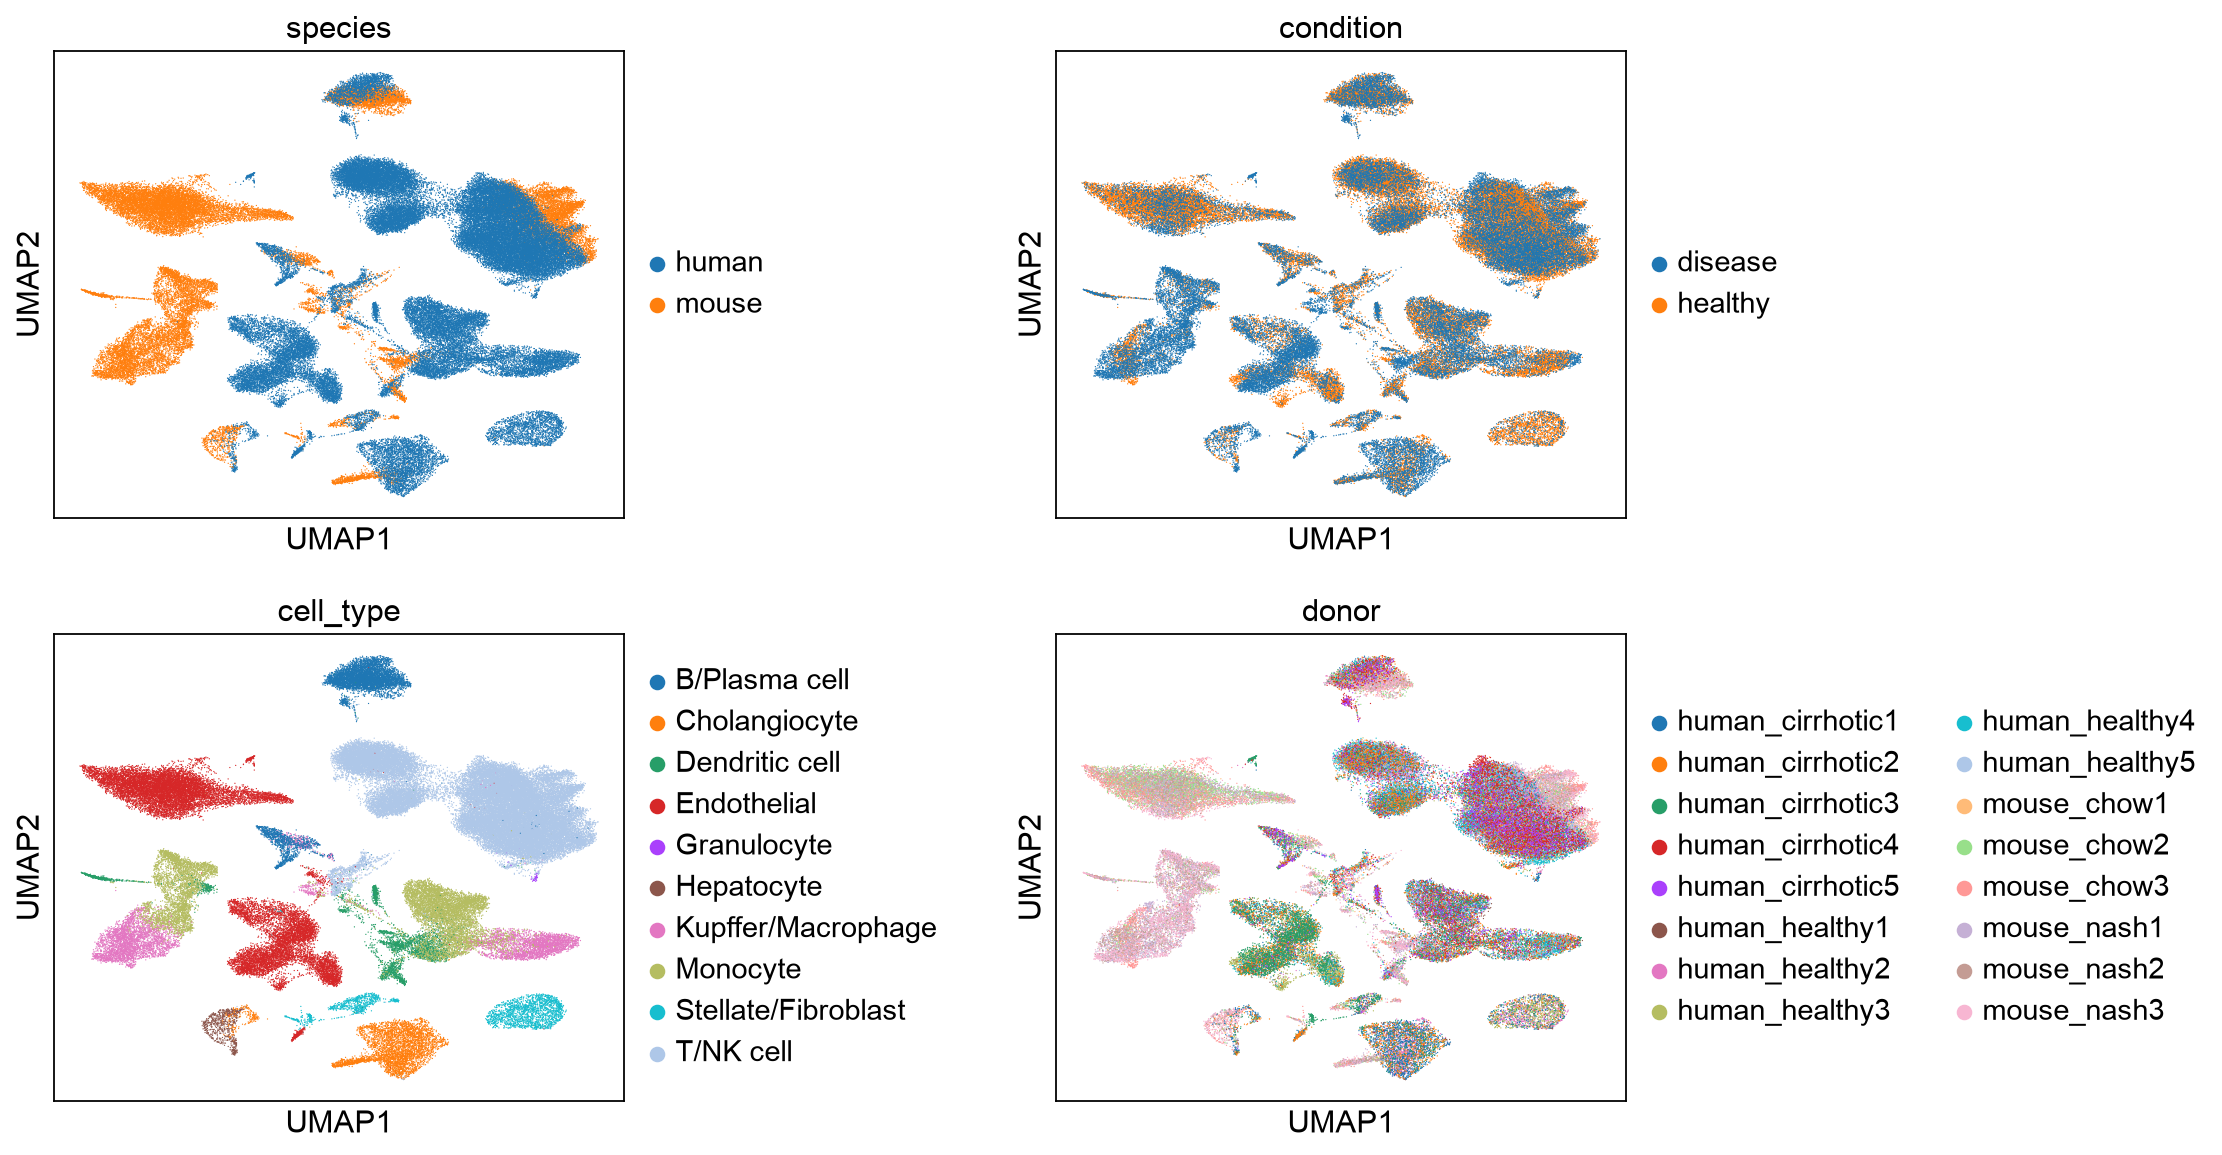

In [2]:
fig = sc.pl.umap(adata, color=["species", "condition", "cell_type", "donor"], ncols=2, wspace=0.6, return_fig=True)
fig.savefig(os.path.join(FIG, "umap_by_label.png"), bbox_inches="tight"); plt.show()

In [3]:
# For each cell type: what share of its cells sit in a Leiden cluster where the *other* species
# also makes up at least 10%? High = the two species were brought together.
sp = pd.crosstab(adata.obs["leiden"], adata.obs["species"], normalize="index")
mixed = sp[(sp > 0.10).all(axis=1)].index
adata.obs["in_mixed_cluster"] = adata.obs["leiden"].isin(mixed)
mix = adata.obs.groupby(["cell_type", "species"], observed=True)["in_mixed_cluster"].mean().unstack().round(2)
mix["n_cells"] = adata.obs["cell_type"].value_counts()
print(f"{len(mixed)} of {sp.shape[0]} Leiden clusters hold both species (>=10% each)")
mix.to_csv(os.path.join(FIG, "species_mixing_by_celltype.csv")); mix

10 of 31 Leiden clusters hold both species (>=10% each)


species,human,mouse,n_cells
cell_type,,,
B/Plasma cell,0.94,1.00,6577
Cholangiocyte,1.00,1.00,4268
Dendritic cell,0.74,0.66,3485
Endothelial,0.03,0.01,18476
Granulocyte,0.02,NaN,53
Hepatocyte,1.00,1.00,727
Kupffer/Macrophage,0.07,0.12,6782
Monocyte,0.26,0.03,10658
Stellate/Fibroblast,0.21,0.98,2692


In [4]:
# Largest share of any single donor within each cluster (a value near 1 = a donor-only island)
dom = pd.crosstab(adata.obs["leiden"], adata.obs["donor"], normalize="index").max(axis=1).sort_values(ascending=False)
print("clusters dominated (>80%) by one donor:", list(dom[dom > 0.8].index))
dom.head(10).round(2)

clusters dominated (>80%) by one donor: ['26']


leiden
26    0.88
6     0.80
30    0.50
24    0.50
0     0.41
1     0.39
5     0.36
27    0.35
19    0.34
3     0.33
dtype: float64

## 2. Known answer: TREM2 macrophages expand in disease

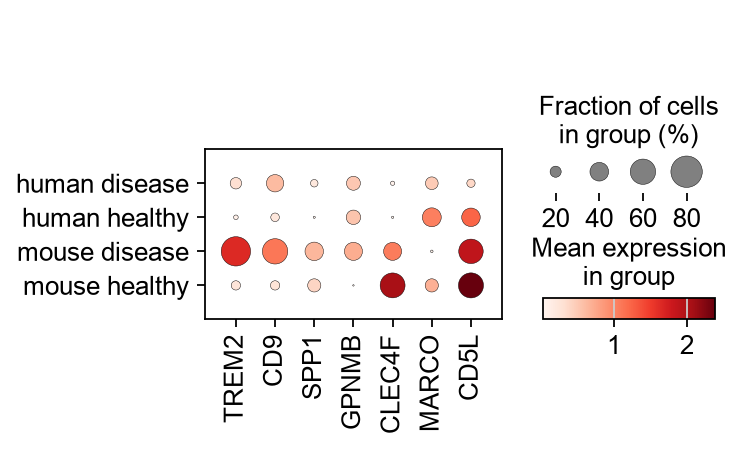

In [5]:
genes = ["TREM2", "CD9", "SPP1", "GPNMB", "CLEC4F", "MARCO", "CD5L"]
genes = [g for g in genes if g in adata.var_names]
myeloid = adata[adata.obs["cell_type"].isin(["Kupffer/Macrophage", "Monocyte"])].copy()
myeloid.obs["group"] = (myeloid.obs["species"].astype(str) + " " + myeloid.obs["condition"].astype(str)).astype("category")
sc.pl.dotplot(myeloid, genes, groupby="group", show=False)
plt.savefig(os.path.join(FIG, "trem2_dotplot.png"), bbox_inches="tight"); plt.show()

In [6]:
# A cell counts as TREM2+CD9+ if both genes are detected. Share among myeloid cells, per donor,
# so each mouse/person counts once (cells from one donor are not independent).
X = myeloid[:, ["TREM2", "CD9"]].X
X = X.toarray() if hasattr(X, "toarray") else X
myeloid.obs["trem2_cd9"] = (X > 0).all(axis=1)
per_donor = myeloid.obs.groupby(["species", "condition", "donor"], observed=True)["trem2_cd9"].mean().rename("share TREM2+CD9+")
print(per_donor.round(3).to_string())
summary = per_donor.groupby(["species", "condition"]).agg(["mean", "count"]).round(3)
summary.to_csv(os.path.join(FIG, "trem2_cd9_share.csv")); summary

species  condition  donor           
human    disease    human_cirrhotic1    0.063
                    human_cirrhotic2    0.123
                    human_cirrhotic3    0.176
                    human_cirrhotic4    0.184
                    human_cirrhotic5    0.145
         healthy    human_healthy1      0.006
                    human_healthy2      0.012
                    human_healthy3      0.114
                    human_healthy4      0.045
                    human_healthy5      0.036
mouse    disease    mouse_nash1         0.438
                    mouse_nash2         0.418
                    mouse_nash3         0.647
         healthy    mouse_chow1         0.047
                    mouse_chow2         0.035
                    mouse_chow3         0.055


/var/folders/pl/6hjybn0914n9blw5dxwd81580000gn/T/ipykernel_25801/2887401149.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary = per_donor.groupby(["species", "condition"]).agg(["mean", "count"]).round(3)


mean  count
species condition              
human   disease    0.138      5
        healthy    0.043      5
mouse   disease    0.501      3
        healthy    0.046      3

In [7]:
for s in ["mouse", "human"]:
    h = per_donor.loc[(s, "healthy")].mean(); d = per_donor.loc[(s, "disease")].mean()
    print(f"{s}: TREM2+CD9+ share of myeloid cells healthy {h:.3f} -> disease {d:.3f}  ({'UP' if d > h else 'not up'} in disease)")

mouse: TREM2+CD9+ share of myeloid cells healthy 0.046 -> disease 0.501  (UP in disease)
human: TREM2+CD9+ share of myeloid cells healthy 0.043 -> disease 0.138  (UP in disease)


## 3. Cells kept at each step (for the progress report)

In [8]:
steps = pd.concat([pd.read_csv(os.path.join("figures", f, "cells_per_sample.csv"), index_col=0).loc[["total"]].rename(index={"total": f.split("_", 1)[1]})
                   for f in ["01_xiong", "02_ramachandran"]])
steps["in merged map"] = [int((adata.obs["dataset"] == d).sum()) for d in ["xiong", "ramachandran"]]
steps.to_csv(os.path.join(FIG, "cells_per_step.csv")); steps

,loaded,after QC,after doublets,in merged map
sample,,,,
xiong,33168,32584,32536,32536
ramachandran,62210,60879,60541,60541
